# Results Visualization
Reads `Results_Tables_30runs.xlsx` directly. Produces the same 3 figures as original format.

**Output files:**
- `Table5_Win_Loss.png`
- `Table6_Green_Heatmap.png`
- `Table7_MFR_pre.png`

## Cell 1: Imports

In [3]:
import openpyxl
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']

print("Imports OK")

Imports OK


## Cell 2: Load Excel + Compute Statistics

In [5]:
# =============================================================================
# Load Results_Tables_30runs.xlsx and compute statistics
# =============================================================================
wb = openpyxl.load_workbook('Results_Tables_30runs.xlsx', data_only=True)

def read_sheet(ws):
    headers = [c.value for c in next(ws.iter_rows(min_row=1, max_row=1))]
    methods = headers[3:]
    data = {}
    current_metric = None
    for row in ws.iter_rows(min_row=2, values_only=True):
        if row[0]: current_metric = row[0]
        ds = row[1]
        if not ds or not current_metric: continue
        if current_metric not in data: data[current_metric] = {}
        data[current_metric][ds] = {}
        for i, m in enumerate(methods):
            val = row[3+i]
            if val and isinstance(val, str) and '±' in val:
                try:
                    mean, std = val.split('±')
                    data[current_metric][ds][m] = float(mean)
                except: pass
            elif isinstance(val, (int, float)) and val is not None:
                data[current_metric][ds][m] = float(val)
    return data, methods

s1u, METHODS = read_sheet(wb['S1 Utility'])
s1f, _       = read_sheet(wb['S1 Fairness'])
s2u, _       = read_sheet(wb['S2 Utility'])
s2f, _       = read_sheet(wb['S2 Fairness'])

# ORIGINAL (Reviewer 3, Comment 6 -- kept for reference, not executed):
# HIGHER = {'Silh. ↑','CHI ↑','BCSS ↑','V-Ratio ↑','Balance ↑','Entropy ↑'}
# LOWER  = {'SSE ↓','DBI ↓','SPD ↓','|DI-1| ↓'}

NON_KM = [m for m in METHODS if m != 'K-Means']
# FIXED (Reviewer 3, Comment 6): 'CHI ↑' and 'BCSS ↑' removed -- these
# columns no longer exist in Results_Tables_30runs.xlsx now that
# Calinski_Harabasz and BCSS have been dropped as redundant with
# Variance_Ratio and Inertia respectively (see Results_Normalized.ipynb).
HIGHER = {'Silh. ↑','V-Ratio ↑','Balance ↑','Entropy ↑'}
LOWER  = {'SSE ↓','DBI ↓','SPD ↓','|DI-1| ↓'}

# FIXED (Eq. 9, "A_i outperforms A_j"): a tie with K-Means is no longer counted
# as a win (previously v >= km / v <= km). Ties are counted separately.
# def wins_vs_kmeans(data, return_ties=False):
#     wins = {m: 0 for m in NON_KM}
#     ties = {m: 0 for m in NON_KM}
#     for metric, ds_dict in data.items():
#         for ds, mv in ds_dict.items():
#             km = mv.get('K-Means')
#             if km is None: continue
#             for m in NON_KM:
#                 v = mv.get(m)
#                 if v is None: continue
#                 if abs(v - km) < 1e-9:
#                     ties[m] += 1
#                 elif (metric in HIGHER and v > km) or (metric in LOWER and v < km):
#                     wins[m] += 1
#     return (wins, ties) if return_ties else wins

# FIXED (Reviewer 3, Comment 9): wins, ties and losses tracked separately
def wins_vs_kmeans(data, return_ties=False, return_all=False):
    wins = {m: 0 for m in NON_KM}; ties = {m: 0 for m in NON_KM}; losses = {m: 0 for m in NON_KM}
    for metric, ds_dict in data.items():
        for ds, mv in ds_dict.items():
            km = mv.get('K-Means')
            if km is None: continue
            for m in NON_KM:
                v = mv.get(m)
                if v is None: continue
                if abs(v - km) < 1e-9:
                    ties[m] += 1
                elif (metric in HIGHER and v > km) or (metric in LOWER and v < km):
                    wins[m] += 1
                else:
                    losses[m] += 1
    if return_all: return wins, ties, losses
    return (wins, ties) if return_ties else wins

def best_score(data):
    best = {m: 0 for m in METHODS}
    for metric, ds_dict in data.items():
        for ds, mv in ds_dict.items():
            vals = {m: mv[m] for m in METHODS if m in mv}
            if not vals: continue
            best_val = max(vals.values()) if metric in HIGHER else min(vals.values())
            for m, v in vals.items():
                if abs(v - best_val) < 1e-9:
                    best[m] += 1
    return best

# ORIGINAL (Reviewer 3, Comment 6 -- kept for reference, not executed):
# def mean_rank(data):
#     """Mean fractional rank (1/7 = best, 7/7 = worst) — scaled to rank number 1-7"""
#     ranks = {m: [] for m in METHODS}
#     for metric, ds_dict in data.items():
#         for ds, mv in ds_dict.items():
#             vals = {m: mv[m] for m in METHODS if m in mv}
#             if len(vals) < 2: continue
#             sorted_m = sorted(vals, key=vals.get, reverse=(metric in HIGHER))
#             for r, m in enumerate(sorted_m, 1):
#                 ranks[m].append(r)   # rank 1 = best, 7 = worst
#     return {m: float(np.mean(v)) if v else np.nan for m, v in ranks.items()}

# FIXED (Reviewer 3, Comment 6): added an optional `methods` parameter so
# callers can compute MFR over a subset of methods (used below to exclude
# Rawlsian from Figure 4 specifically -- Win-Loss and Best-Score-Frequency
# are unaffected by this comment and continue to use the full METHODS list).
def mean_rank(data, methods=None):
    """Mean fractional rank (1 = best). FIXED: tied values now share the average
    rank (fractional ranking, Eq. 13) instead of being ordered arbitrarily."""
    from scipy.stats import rankdata
    methods = methods if methods is not None else METHODS
    ranks = {m: [] for m in methods}
    for metric, ds_dict in data.items():
        for ds, mv in ds_dict.items():
            vals = {m: mv[m] for m in methods if m in mv}
            if len(vals) < 2: continue
            ms = list(vals)
            arr = np.array([vals[m] for m in ms])
            r = rankdata(-arr if metric in HIGHER else arr, method='average')
            for m, rr in zip(ms, r):
                ranks[m].append(rr)
    return {m: float(np.mean(v)) if v else np.nan for m, v in ranks.items()}

# Compute
w_s1u  = wins_vs_kmeans(s1u);  w_s1f  = wins_vs_kmeans(s1f)
w_s2u  = wins_vs_kmeans(s2u);  w_s2f  = wins_vs_kmeans(s2f)
bs_s1u = best_score(s1u);      bs_s1f = best_score(s1f)
bs_s2u = best_score(s2u);      bs_s2f = best_score(s2f)
mr_s1u = mean_rank(s1u);       mr_s1f = mean_rank(s1f)
mr_s2u = mean_rank(s2u);       mr_s2f = mean_rank(s2f)

print(f"Methods: {METHODS}")
_, t_s1u = wins_vs_kmeans(s1u, True); _, t_s1f = wins_vs_kmeans(s1f, True)
_, t_s2u = wins_vs_kmeans(s2u, True); _, t_s2f = wins_vs_kmeans(s2f, True)
print(f"Ties with KM: S1U {t_s1u} | S1F {t_s1f} | S2U {t_s2u} | S2F {t_s2f}")
print(f"Win vs KM (S1 Utility):  {w_s1u}")
print(f"Win vs KM (S1 Fairness): {w_s1f}")
print(f"Win vs KM (S2 Utility):  {w_s2u}")
print(f"Win vs KM (S2 Fairness): {w_s2f}")
print(f"Mean Rank S1U: {{{', '.join(f'{k}: {v:.2f}' for k,v in mr_s1u.items())}}}")
print(f"Mean Rank S1F: {{{', '.join(f'{k}: {v:.2f}' for k,v in mr_s1f.items())}}}")

Methods: ['K-Means', 'Fairlet', 'BFKM', 'CCF', 'PP-NFP', 'PP-Gini', 'Rawlsian']
Ties with KM: S1U {'Fairlet': 0, 'BFKM': 2, 'CCF': 0, 'PP-NFP': 30, 'PP-Gini': 32, 'Rawlsian': 20} | S1F {'Fairlet': 0, 'BFKM': 0, 'CCF': 3, 'PP-NFP': 27, 'PP-Gini': 30, 'Rawlsian': 8} | S2U {'Fairlet': 0, 'BFKM': 2, 'CCF': 1, 'PP-NFP': 33, 'PP-Gini': 32, 'Rawlsian': 14} | S2F {'Fairlet': 0, 'BFKM': 0, 'CCF': 3, 'PP-NFP': 27, 'PP-Gini': 30, 'Rawlsian': 8}
Win vs KM (S1 Utility):  {'Fairlet': 2, 'BFKM': 13, 'CCF': 3, 'PP-NFP': 8, 'PP-Gini': 0, 'Rawlsian': 10}
Win vs KM (S1 Fairness): {'Fairlet': 58, 'BFKM': 40, 'CCF': 30, 'PP-NFP': 44, 'PP-Gini': 36, 'Rawlsian': 34}
Win vs KM (S2 Utility):  {'Fairlet': 2, 'BFKM': 24, 'CCF': 9, 'PP-NFP': 12, 'PP-Gini': 11, 'Rawlsian': 19}
Win vs KM (S2 Fairness): {'Fairlet': 60, 'BFKM': 51, 'CCF': 29, 'PP-NFP': 40, 'PP-Gini': 31, 'Rawlsian': 38}
Mean Rank S1U: {K-Means: 2.08, Fairlet: 6.81, BFKM: 4.50, CCF: 4.56, PP-NFP: 2.78, PP-Gini: 3.30, Rawlsian: 3.98}
Mean Rank S1F: {K-

## Cell 3: Figure 1 — Win-Loss vs K-Means

In [7]:
# data = {
#     'Method':        NON_KM,
#     'Utility (S1)':  [w_s1u[m] for m in NON_KM],
#     'Utility (S2)':  [w_s2u[m] for m in NON_KM],
#     'Fairness (S1)': [w_s1f[m] for m in NON_KM],
#     'Fairness (S2)': [w_s2f[m] for m in NON_KM],
# }
# df = pd.DataFrame(data).melt(id_vars='Method', var_name='Metric_Strategy', value_name='Wins')

# plt.figure(figsize=(13, 8), dpi=720)          
# sns.set_style("whitegrid")

# palette = {
#     'Utility (S1)': '#1f77b4', 'Utility (S2)': '#aec7e8',
#     'Fairness (S1)': '#2ca02c', 'Fairness (S2)': '#98df8a'
# }
# ax = sns.barplot(data=df, x='Method', y='Wins', hue='Metric_Strategy', palette=palette)

# for label in ax.get_xticklabels():
#     if label.get_text() == 'PP-NFP':
#         label.set_color('red')
#         label.set_fontsize(18)               
#     else:
#         label.set_fontsize(18)                
# for container in ax.containers:
#     labels = [f'{int(v.get_height())}' if v.get_height() >= 0 else '' for v in container]
#     ax.bar_label(container, labels=labels, padding=5, fontsize=15, color='black') 

# plt.title('Figure 1: Win-Loss Comparison Against K-Means Baseline',
#           fontsize=20, fontweight='bold', pad=20)  
# plt.ylabel('Total Wins', fontsize=20)               
# plt.xlabel('Clustering Method', fontsize=20)         
# ax.tick_params(axis='y', labelsize=16)           

# ax.set_ylim(0, df['Wins'].max() * 1.18)
# plt.legend(title='Metric & Strategy',
#            loc='upper left',
#            fontsize=16,          
#            title_fontsize=16,    
#            frameon=True,
#            framealpha=0.8,
#            ncol=1)
# plt.tight_layout()
# plt.savefig('Table5_Win_Loss.png', dpi=720, bbox_inches='tight')   
# print("✓ Saved: Table5_Win_Loss.png")
# plt.show()

# FIXED (Reviewer 3, Comment 9): Win-Tie-Loss figure (ties shown separately)
scen = {'Utility (S1)': s1u, 'Utility (S2)': s2u,
        'Fairness (S1)': s1f, 'Fairness (S2)': s2f}
palette = {'Utility (S1)': '#1f77b4', 'Utility (S2)': '#aec7e8',
           'Fairness (S1)': '#2ca02c', 'Fairness (S2)': '#98df8a'}

wtl_rows = []
for sc, d in scen.items():
    w, t, l = wins_vs_kmeans(d, return_all=True)
    for m in NON_KM:
        wtl_rows.append({'Scenario': sc, 'Method': m, 'Win': w[m], 'Tie': t[m], 'Loss': l[m]})
wtl = pd.DataFrame(wtl_rows)
wtl.to_csv('Table5_Win_Tie_Loss.csv', index=False)
print(wtl.pivot(index='Method', columns='Scenario', values=['Win','Tie','Loss']))

fig, ax = plt.subplots(figsize=(13, 8), dpi=720)
x = np.arange(len(NON_KM)); bw = 0.2
for j, sc in enumerate(scen):
    sub = wtl[wtl['Scenario'] == sc].set_index('Method').loc[NON_KM]
    pos = x + (j - 1.5) * bw
    ax.bar(pos, sub['Win'], bw, color=palette[sc], edgecolor='black', label=f'{sc} – Win')
    ax.bar(pos, sub['Tie'], bw, bottom=sub['Win'], color=palette[sc],
           edgecolor='black', hatch='//', alpha=0.6)
    for p, wv, tv in zip(pos, sub['Win'], sub['Tie']):
        ax.text(p, wv + tv + 0.8, f'{wv}' + (f'/{tv}' if tv else ''), ha='center', fontsize=12)

from matplotlib.patches import Patch
handles = [Patch(facecolor=palette[s], edgecolor='black', label=s) for s in scen]
handles.append(Patch(facecolor='white', edgecolor='black', hatch='//', label='Labels: wins/ties'))
ax.legend(handles=handles, title='Metric & Strategy', loc='upper left',
          fontsize=14, title_fontsize=14, framealpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(NON_KM, fontsize=18)
for lab in ax.get_xticklabels():
    if lab.get_text() == 'PP-NFP': lab.set_color('red')
ax.tick_params(axis='y', labelsize=16)
ax.set_ylim(0, (wtl['Win'] + wtl['Tie']).max() * 1.25)
ax.set_title('Figure 2: Win-Tie-Loss Comparison Against K-Means Baseline',
             fontsize=20, fontweight='bold', pad=20)
ax.set_ylabel('Count (out of 72 comparisons per scenario)', fontsize=18)
ax.set_xlabel('Clustering Method', fontsize=20)
plt.tight_layout()
plt.savefig('Table5_Win_Loss.png', dpi=720, bbox_inches='tight')
print("✓ Saved: Table5_Win_Loss.png")
plt.show()

                   Win                                                   Tie  \
Scenario Fairness (S1) Fairness (S2) Utility (S1) Utility (S2) Fairness (S1)   
Method                                                                         
BFKM                40            51           13           24             0   
CCF                 30            29            3            9             3   
Fairlet             58            60            2            2             0   
PP-Gini             36            31            0           11            30   
PP-NFP              44            40            8           12            27   
Rawlsian            34            38           10           19             8   

                                                          Loss                \
Scenario Fairness (S2) Utility (S1) Utility (S2) Fairness (S1) Fairness (S2)   
Method                                                                         
BFKM                 0            2    

## Cell 4: Figure 2 — Best-Score Heatmap

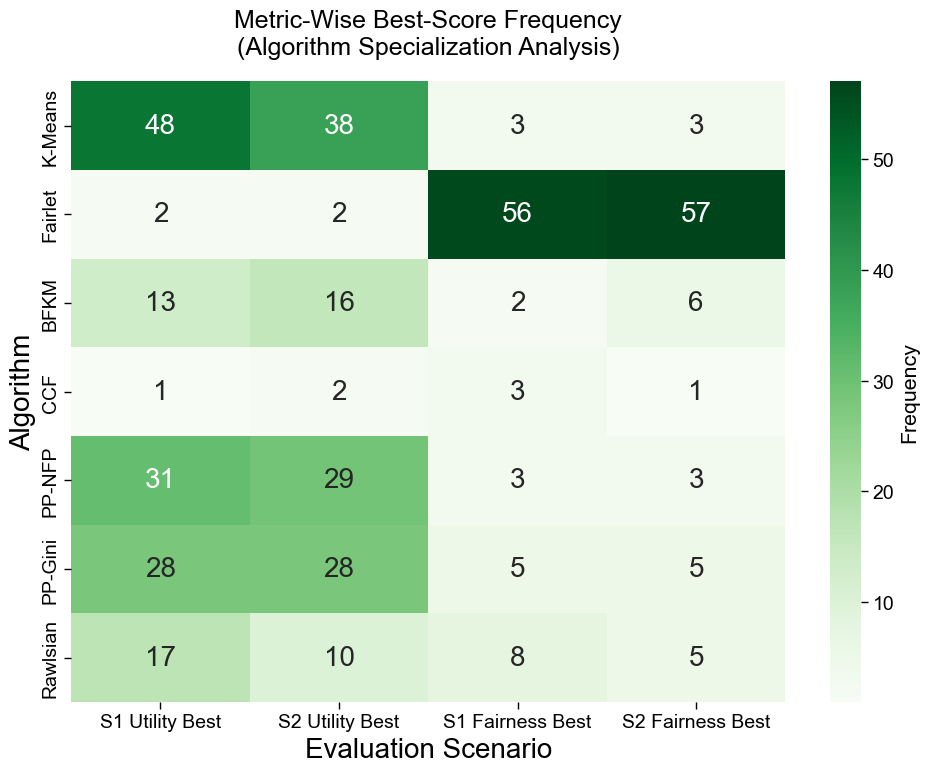

In [9]:
algorithms = METHODS
columns    = ['S1 Utility Best', 'S2 Utility Best', 'S1 Fairness Best', 'S2 Fairness Best']
scores = np.array([
    [bs_s1u[m], bs_s2u[m], bs_s1f[m], bs_s2f[m]]
    for m in algorithms
])

plt.figure(figsize=(10, 8))         
sns.set_context("paper", font_scale=1.6)  

ax = sns.heatmap(scores,
                 annot=True,
                 fmt="d",
                 annot_kws={"size": 20},  
                 cmap="Greens",
                 xticklabels=columns,
                 yticklabels=algorithms,
                 # linewidths=0.5,            
                 cbar_kws={'label': 'Frequency'})

ax.tick_params(axis='both', which='major', labelsize=14)  
plt.title('Metric-Wise Best-Score Frequency\n(Algorithm Specialization Analysis)',
          fontsize=18, pad=20)       
plt.xlabel('Evaluation Scenario', fontsize=20)  
plt.ylabel('Algorithm', fontsize=20)    
plt.tight_layout()
plt.savefig('Table6_Green_Heatmap.png', dpi=880, bbox_inches='tight')

## Cell 5: Figure 3 — Performance Map

In [11]:
import openpyxl
import numpy as np
import pandas as pd

wb = openpyxl.load_workbook('Results_Tables_30runs.xlsx', data_only=True)

def read_sheet(ws):
    headers = [c.value for c in next(ws.iter_rows(min_row=1, max_row=1))]
    methods = headers[3:]
    data = {}
    current_metric = None
    for row in ws.iter_rows(min_row=2, values_only=True):
        if row[0]: current_metric = row[0]
        ds = row[1]
        if not ds or not current_metric: continue
        if current_metric not in data: data[current_metric] = {}
        data[current_metric][ds] = {}
        for i, m in enumerate(methods):
            val = row[3+i]
            if val and isinstance(val, str) and '±' in val:
                try:
                    data[current_metric][ds][m] = float(val.split('±')[0])
                except: pass
            elif isinstance(val, (int, float)) and val is not None:
                data[current_metric][ds][m] = float(val)
    return data, methods

s1u, METHODS = read_sheet(wb['S1 Utility'])
s1f, _       = read_sheet(wb['S1 Fairness'])
s2u, _       = read_sheet(wb['S2 Utility'])
s2f, _       = read_sheet(wb['S2 Fairness'])

# ORIGINAL (Reviewer 3, Comment 6 -- kept for reference, not executed):
# HIGHER = {'Silh. ↑','CHI ↑','BCSS ↑','V-Ratio ↑','Balance ↑','Entropy ↑'}
# LOWER  = {'SSE ↓','DBI ↓','SPD ↓','|DI-1| ↓'}

# FIXED (Reviewer 3, Comment 6): 'CHI ↑' and 'BCSS ↑' removed -- redundant
# columns dropped upstream in Results_Normalized.ipynb.
HIGHER = {'Silh. ↑','V-Ratio ↑','Balance ↑','Entropy ↑'}
LOWER  = {'SSE ↓','DBI ↓','SPD ↓','|DI-1| ↓'}

def compute_ranks(data, sheet_name, methods=None):
    methods = methods if methods is not None else METHODS
    rows = []
    for metric, ds_dict in data.items():
        higher = metric in HIGHER
        for ds, mv in ds_dict.items():
            vals = {m: mv[m] for m in methods if m in mv}
            if not vals: continue

            # Sort: best first
            sorted_methods = sorted(
                vals.keys(),
                key=lambda m: -vals[m] if higher else vals[m]
            )

            # Standard average rank for all ties (K-Means treated same as others)
            ranks = {}
            i = 0
            while i < len(sorted_methods):
                m = sorted_methods[i]
                v = vals[m]
                # Find all methods with same value
                tie_group = [m2 for m2 in sorted_methods[i:]
                             if abs(vals[m2] - v) < 1e-9]
                n_tie = len(tie_group)
                # Average rank for all tied methods
                avg_rank = np.mean([i + j + 1 for j in range(n_tie)])
                for m2 in tie_group:
                    ranks[m2] = avg_rank
                i += n_tie

            row = {'Sheet': sheet_name, 'Metric': metric, 'Dataset': ds}
            for m in methods:
                row[m] = ranks.get(m, np.nan)
            rows.append(row)
    return rows


all_rows = []
for data, name in [(s1u,'S1 Utility'),(s1f,'S1 Fairness'),
                   (s2u,'S2 Utility'),(s2f,'S2 Fairness')]:
    all_rows.extend(compute_ranks(data, name))

rank_df = pd.DataFrame(all_rows)

# Mean rank per method per sheet
print("=== MEAN RANK PER METHOD PER SHEET (lower = better) ===")
for sheet in ['S1 Utility','S1 Fairness','S2 Utility','S2 Fairness']:
    sub = rank_df[rank_df['Sheet']==sheet]
    means = sub[METHODS].mean().round(3)
    print(f"\n{sheet}:")
    print(means.to_string())

# Overall mean rank (avg across all sheets)
print("\n=== OVERALL MEAN RANK (all metrics, all datasets, S1+S2) ===")
print(rank_df[METHODS].mean().round(3).to_string())

# Save full rank table
rank_df.to_csv('rank_table_all.csv', index=False)
print("\n✓ Saved: rank_table_all.csv")

# FIXED: Figure 4 (MFR) excludes Rawlsian, so ranks must be computed among the
# remaining six methods only (previously the 1-7 ranks still included Rawlsian,
# so its position shifted the other methods' ranks).
_MFR_METHODS = [m for m in METHODS if m != 'Rawlsian']
_rows = []
for data, name in [(s1u,'S1 Utility'),(s1f,'S1 Fairness'),(s2u,'S2 Utility'),(s2f,'S2 Fairness')]:
    _rows.extend(compute_ranks(data, name, methods=_MFR_METHODS))
pd.DataFrame(_rows).to_csv('rank_table_mfr_no_rawlsian.csv', index=False)
print("✓ Saved: rank_table_mfr_no_rawlsian.csv")

# Pivot: mean rank per method per metric
print("\n=== MEAN RANK PER METRIC (across all datasets, S1+S2 combined) ===")
pivot = rank_df.groupby('Metric')[METHODS].mean().round(3)
print(pivot.to_string())
pivot.to_csv('rank_by_metric.csv')
print("✓ Saved: rank_by_metric.csv")

=== MEAN RANK PER METHOD PER SHEET (lower = better) ===

S1 Utility:
K-Means     2.083
Fairlet     6.806
BFKM        4.500
CCF         4.556
PP-NFP      2.778
PP-Gini     3.299
Rawlsian    3.979

S1 Fairness:
K-Means     4.833
Fairlet     2.153
BFKM        4.389
CCF         5.160
PP-NFP      3.660
PP-Gini     3.486
Rawlsian    4.319

S2 Utility:
K-Means     2.639
Fairlet     6.778
BFKM        4.396
CCF         4.493
PP-NFP      2.979
PP-Gini     3.021
Rawlsian    3.694

S2 Fairness:
K-Means     4.931
Fairlet     2.042
BFKM        3.549
CCF         5.542
PP-NFP      3.917
PP-Gini     3.854
Rawlsian    4.167

=== OVERALL MEAN RANK (all metrics, all datasets, S1+S2) ===
K-Means     3.622
Fairlet     4.444
BFKM        4.208
CCF         4.938
PP-NFP      3.333
PP-Gini     3.415
Rawlsian    4.040

✓ Saved: rank_table_all.csv
✓ Saved: rank_table_mfr_no_rawlsian.csv

=== MEAN RANK PER METRIC (across all datasets, S1+S2 combined) ===
           K-Means  Fairlet   BFKM    CCF  PP-NFP  PP-Gini  R

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FormatStrFormatter

# Load rank data
rank_all = pd.read_csv('rank_table_mfr_no_rawlsian.csv')   # FIXED: ranks computed without Rawlsian

# ORIGINAL (Reviewer 3, Comment 1 & 6 -- kept for reference, not executed):
# UTIL_METRICS = ['SSE ↓', 'Silh. ↑', 'CHI ↑', 'DBI ↓', 'BCSS ↑', 'V-Ratio ↑']
# FAIR_METRICS = ['Balance ↑', 'SPD ↓', '|DI-1| ↓', 'Entropy ↑']
#
# util_ranks = rank_all[rank_all['Metric'].isin(UTIL_METRICS)][METHODS].mean()
# fair_ranks = rank_all[rank_all['Metric'].isin(FAIR_METRICS)][METHODS].mean()
#
# labels        = METHODS
# fairness_rank = [round(fair_ranks[m], 2) for m in labels]
# utility_rank  = [round(util_ranks[m], 2) for m in labels]

# FIXED (Reviewer 3, Comment 6): 'CHI ↑' and 'BCSS ↑' removed -- redundant
# columns dropped upstream in Results_Normalized.ipynb.
UTIL_METRICS = ['SSE ↓', 'Silh. ↑', 'DBI ↓', 'V-Ratio ↑']
FAIR_METRICS = ['Balance ↑', 'SPD ↓', '|DI-1| ↓', 'Entropy ↑']

# FIXED (Reviewer 1, Comment 1): Rawlsian is excluded from Figure 4 (the
# Mean Fractional Ranking / utility-fairness quadrant plot) specifically,
# since the group-representation metrics used for this ranking (Balance,
# SPD, |DI-1|, Entropy) don't capture the individual/worst-case fairness
# notion Rawlsian actually optimizes -- comparing it on this axis isn't a
# fair comparison of what it was designed to do. Rawlsian is NOT excluded
# from Win-Loss (Figure 2) or Best-Score-Frequency (Figure 3) above, which
# are unaffected by this comment and still report it alongside the other
# six methods.
MFR_METHODS = [m for m in METHODS if m != 'Rawlsian']

util_ranks = rank_all[rank_all['Metric'].isin(UTIL_METRICS)][MFR_METHODS].mean()
fair_ranks = rank_all[rank_all['Metric'].isin(FAIR_METRICS)][MFR_METHODS].mean()

labels        = MFR_METHODS
fairness_rank = [round(fair_ranks[m], 2) for m in labels]
utility_rank  = [round(util_ranks[m], 2) for m in labels]

print("Fairness ranks:", dict(zip(labels, fairness_rank)))
print("Utility ranks: ", dict(zip(labels, utility_rank)))

plt.figure(figsize=(11, 9), dpi=880)          
plt.rcParams['axes.facecolor'] = '#f9f9f9'
plt.grid(True, linestyle='--', alpha=0.6, zorder=0)

colors = ['#e74c3c' if x == 'PP-NFP' else '#3498db' for x in labels]
plt.scatter(fairness_rank, utility_rank, s=350, c=colors,          
            edgecolors='black', linewidth=1.5, zorder=3)

for i, txt in enumerate(labels):
    x_offset = 12
    align = 'left'
    # NOTE: 'Rawlsian' in this list is now inert -- Rawlsian is excluded from
    # `labels` (MFR_METHODS) above, so this branch only ever matches
    # 'PP-NFP' or 'Fairlet' in practice. Left as-is since it's harmless.
    if txt in ['PP-NFP', 'Rawlsian','Fairlet']:
        x_offset = -12
        align = 'right'
    plt.annotate(txt, (fairness_rank[i], utility_rank[i]),
                 xytext=(x_offset, 10),
                 textcoords='offset points',
                 fontsize=18, fontweight='bold', ha=align,           
                 bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7, ec='none'))

x_min = max(fairness_rank) + 0.2
x_max = min(fairness_rank) - 0.1
y_min = max(utility_rank)  + 0.3
y_max = min(utility_rank)  - 0.7
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.axvline(x=4, color='black', linestyle='-', linewidth=1.5, alpha=0.3)
plt.axhline(y=4, color='black', linestyle='-', linewidth=1.5, alpha=0.3)

plt.text(x_max+0.05, y_max+0.2, "HIGH UTILITY & FAIRNESS",
         color='#27ae60', fontsize=16, fontweight='bold', ha='right')  
plt.text(x_min-0.05, y_max+0.2, "UTILITY FOCUS",
         color='#7f8c8d', fontsize=16, fontweight='bold', ha='left')
plt.text(x_max+0.05, y_min-0.05, "FAIRNESS FOCUS",
         color='#7f8c8d', fontsize=16, fontweight='bold', ha='right')
plt.text(x_min-0.05, y_min-0.05, "LOW PERFORMANCE",
         color='#c0392b', fontsize=16, fontweight='bold', ha='left')

plt.title('Algorithm Performance Map: Mean Fractional Ranking\n'
          '(lower rank value = better | Top-Right Corner is the Optimal Result)',
          fontsize=18, pad=20, fontweight='bold')                     
plt.xlabel('Average Fairness Rank (Rank 1 = Best to Rank 7 = Worst)', fontsize=20, labelpad=10)  
plt.ylabel('Average Utility Rank (Rank 1 = Best to Rank 7 = Worst)', fontsize=20, labelpad=10)

ax = plt.gca()
ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax.tick_params(axis='both', which='major', labelsize=14)            

plt.tight_layout()
plt.savefig('Table7_MFR_pre.png', dpi=880, bbox_inches='tight')     
print("✓ Saved: Table7_MFR_pre.png")
plt.show()

Fairness ranks: {'K-Means': 4.33, 'Fairlet': 1.92, 'BFKM': 3.57, 'CCF': 4.67, 'PP-NFP': 3.29, 'PP-Gini': 3.23}
Utility ranks:  {'K-Means': 2.04, 'Fairlet': 5.83, 'BFKM': 3.85, 'CCF': 3.99, 'PP-NFP': 2.52, 'PP-Gini': 2.77}
✓ Saved: Table7_MFR_pre.png
